# Task 5: Emotion Classification Using Machine Learning

## 1. Text Dataset Preparation

### Library Loading

In [1]:
# File handling libraries
from pathlib import Path

# Data analysis related libraries
import numpy as np
import pandas as pd

# Machine learning libraries
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Visualisation libraries
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt

# Lemmatization and Stop-Word Removal
import stanza
import spacy
from spacy.tokens import Doc
from spacy.lang.lt.stop_words import STOP_WORDS
from collections import Counter

# Word Clouds
from wordcloud import WordCloud

# Text Representation
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer

# Custom functions
import emoclass

c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\__init__.py:82: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  import scipy.linalg  # noqa


In [2]:
# Global colour parameters
static_cmap = ["salmon", "skyblue"]
cmap = LinearSegmentedColormap.from_list("custom", ["#c6fcff", "#ffffff", "#FA8072"])

# Global random seed
random_seed = 20261030

### Loading the EMO Corpus Metadata

In [3]:
emo_metadata = "metadata_of_EMO_dataset.csv"

metadata = pd.read_csv(emo_metadata, header=None)

metadata = metadata[0].str.split("/", n=4, expand=True)
metadata.columns = ["root_dir", "emotion_dir", "speaker_dir", "session_dir", "file_info"]

metadata[["file_name", "speaker_id", "text"]] = metadata["file_info"].str.split("|", n=2, expand=True)
metadata = metadata.drop(columns="file_info")

emotions = {"D": "Joy", "L": "Sadness", "N": "Surprise", "P": "Anger", "Z": "Neutral"}
metadata["emotion"] = metadata["emotion_dir"].map(emotions)

In [4]:
emotion_counts = metadata["emotion"].value_counts()
display(pd.DataFrame({
    "recordings": emotion_counts,
    "share_pct": (emotion_counts / len(metadata) * 100).round(1),
}))

,recordings,share_pct
emotion,,
Anger,72463,20.7
Sadness,71401,20.4
Joy,69642,19.9
Surprise,68103,19.5
Neutral,68087,19.5


### Excluding Texts With Multiple Emotion Labels

In [5]:
texts_emotions = metadata[["text", "emotion"]]

labels_per_text = texts_emotions.groupby("text")["emotion"].transform("nunique")

multi_label_rows = (labels_per_text > 1).sum()
multi_label_texts = texts_emotions.loc[labels_per_text > 1, "text"].nunique()

single_label = texts_emotions[labels_per_text == 1]

print(f"Rows before exclusion: {len(texts_emotions)}")
print(f"Texts with multiple emotion labels: {multi_label_texts} unique texts ({multi_label_rows} rows)")

multi_label = texts_emotions[labels_per_text > 1]
for emotion, group in multi_label.groupby("emotion"):
    print(f"  {emotion}: {group['text'].nunique()} unique texts ({len(group)} rows)")

print(f"Rows after exclusion: {len(single_label)}")

Rows before exclusion: 349696
Texts with multiple emotion labels: 263 unique texts (3548 rows)
  Anger: 125 unique texts (485 rows)
  Joy: 107 unique texts (468 rows)
  Neutral: 47 unique texts (99 rows)
  Sadness: 144 unique texts (571 rows)
  Surprise: 127 unique texts (1925 rows)
Rows after exclusion: 346148


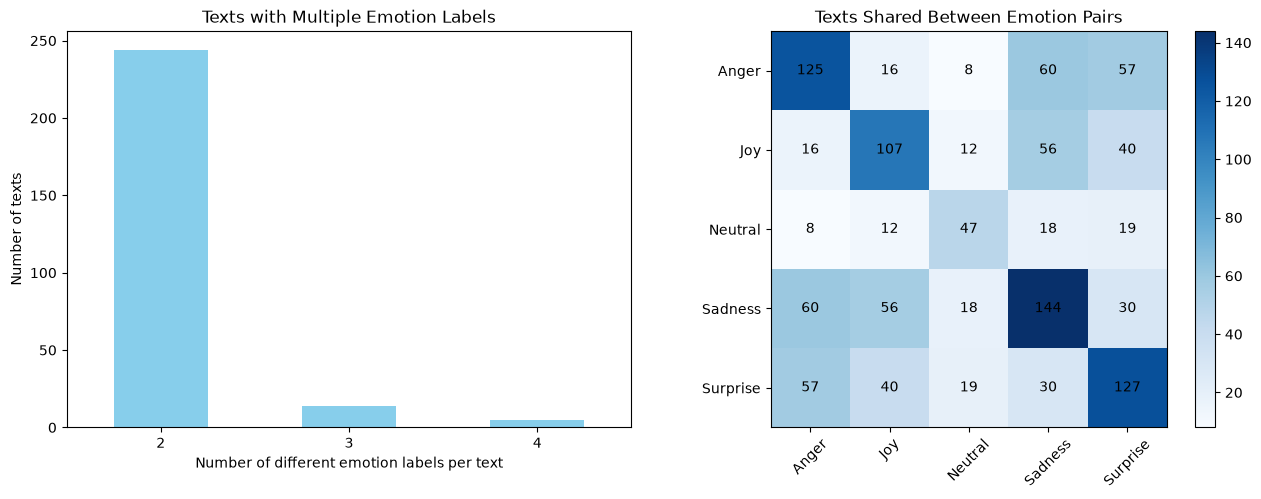

,emotions,recordings
text,,
tiesiog neįtikėtina,"Joy, Surprise",233
negali būti,"Anger, Joy, Sadness, Surprise",225
ar žinojai,"Joy, Surprise",172
neįtikėtinas dalykas,"Joy, Surprise",137
ar girdėjai,"Anger, Surprise",137
čia tai bent,"Joy, Surprise",131
tu manęs nekenti,"Anger, Sadness",66
še tau kad nori,"Joy, Surprise",64
tu pasikeitei,"Anger, Sadness",59


In [6]:
presence = pd.crosstab(texts_emotions["text"], texts_emotions["emotion"]) > 0
multi_presence = presence[presence.sum(axis=1) > 1].astype(int)

shared_texts = multi_presence.T @ multi_presence

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

multi_presence.sum(axis=1).value_counts().sort_index().plot.bar(ax=axes[0], color=static_cmap[1], rot=0)
axes[0].set_title("Texts with Multiple Emotion Labels")
axes[0].set_xlabel("Number of different emotion labels per text")
axes[0].set_ylabel("Number of texts")

im = axes[1].imshow(shared_texts, cmap="Blues")
axes[1].set_xticks(range(len(shared_texts)), shared_texts.columns, rotation=45)
axes[1].set_yticks(range(len(shared_texts)), shared_texts.index)
for i in range(len(shared_texts)):
    for j in range(len(shared_texts)):
        axes[1].text(j, i, shared_texts.iloc[i, j], ha="center", va="center")
axes[1].set_title("Texts Shared Between Emotion Pairs")
fig.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.show()

examples = (
    texts_emotions[texts_emotions["text"].isin(multi_presence.index)]
    .groupby("text")["emotion"]
    .agg(emotions=lambda s: ", ".join(sorted(s.unique())), recordings="size")
    .sort_values("recordings", ascending=False)
    .head(10)
)
examples

### Removing Duplicate Texts

In [7]:
is_duplicate = single_label.duplicated(subset="text", keep="first")
unique_texts = single_label[~is_duplicate]
removed_texts = single_label[is_duplicate]

print(f"Rows before removal: {len(single_label)}")
print(f"Rows removed: {len(removed_texts)} ({len(removed_texts) / len(single_label):.1%})")

rows_before = single_label["emotion"].value_counts()
rows_removed = removed_texts["emotion"].value_counts()
for emotion in sorted(rows_before.index):
    removed = rows_removed.get(emotion, 0)
    print(f"  {emotion}: {removed} ({removed / rows_before[emotion]:.1%})")

print(f"Unique texts kept: {len(unique_texts)}")

Rows before removal: 346148
Rows removed: 211197 (61.0%)
  Anger: 43921 (61.0%)
  Joy: 44177 (63.9%)
  Neutral: 37006 (54.4%)
  Sadness: 44143 (62.3%)
  Surprise: 41950 (63.4%)
Unique texts kept: 134951


### Emotion Class Distribution

In [8]:
per_emotion = pd.DataFrame({
    "before": single_label["emotion"].value_counts(),
    "after": unique_texts["emotion"].value_counts(),
})
per_emotion["removed"] = per_emotion["before"] - per_emotion["after"]
per_emotion["removed_pct"] = (per_emotion["removed"] / per_emotion["before"] * 100).round(1)
per_emotion["share_before_pct"] = (per_emotion["before"] / per_emotion["before"].sum() * 100).round(1)
per_emotion["share_after_pct"] = (per_emotion["after"] / per_emotion["after"].sum() * 100).round(1)
display(per_emotion)

occurrences = single_label["text"].value_counts()
repeated = occurrences[occurrences > 1]
print(f"Texts occurring more than once: {len(repeated)} (max {occurrences.max()} occurrences)")

removed_len = removed_texts["text"].str.split().str.len()
kept_len = unique_texts["text"].str.split().str.len()
print(f"Mean words per text - removed: {removed_len.mean():.1f}, kept: {kept_len.mean():.1f}")

,before,after,removed,removed_pct,share_before_pct,share_after_pct
emotion,,,,,,
Anger,71978,28057,43921,61.0,20.8,20.8
Joy,69174,24997,44177,63.9,20.0,18.5
Neutral,67988,30982,37006,54.4,19.6,23.0
Sadness,70830,26687,44143,62.3,20.5,19.8
Surprise,66178,24228,41950,63.4,19.1,18.0


Texts occurring more than once: 44433 (max 745 occurrences)
Mean words per text - removed: 6.2, kept: 7.2


Texts per Emotion Before and After Removal


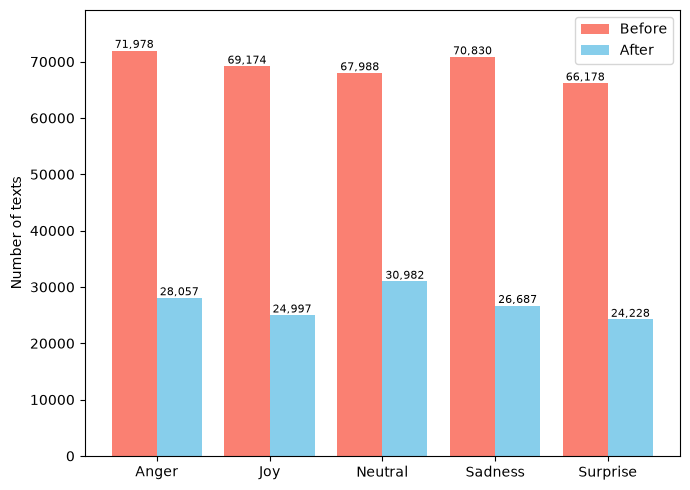

In [9]:
print("Texts per Emotion Before and After Removal")
fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(per_emotion))
bars_before = ax.bar(x - 0.2, per_emotion["before"], width=0.4, label="Before", color=static_cmap[0])
bars_after = ax.bar(x + 0.2, per_emotion["after"], width=0.4, label="After", color=static_cmap[1])
ax.bar_label(bars_before, fmt="{:,.0f}", fontsize=8)
ax.bar_label(bars_after, fmt="{:,.0f}", fontsize=8)
ax.margins(y=0.1)
ax.set_xticks(x, per_emotion.index)
ax.set_ylabel("Number of texts")
ax.legend()
plt.tight_layout()
plt.show()

### Saving the Text Classification Dataset

In [10]:
text_classification_dataset = Path("emotion_text_classification_dataset.csv")

unique_texts.to_csv(text_classification_dataset, index=False, encoding="utf-8")

print(f"Saved {len(unique_texts)} texts to {text_classification_dataset.resolve()}")

Saved 134951 texts to C:\Users\Lenovo\Desktop\vu_masters\1_semester\natural_language_and_speech_processing\6_assignments\task_5\emotion_text_classification_dataset.csv


## 2. Text Analysis

### Text Length

,count,mean,std,min,25%,50%,75%,max
emotion,,,,,,,,
Anger,28057.0,7.38,4.29,2.0,4.0,6.0,10.0,27.0
Joy,24997.0,7.14,4.07,2.0,4.0,6.0,10.0,25.0
Neutral,30982.0,7.74,4.28,2.0,4.0,7.0,11.0,25.0
Sadness,26687.0,6.83,3.93,2.0,4.0,6.0,9.0,28.0
Surprise,24228.0,7.04,3.88,2.0,4.0,6.0,10.0,25.0
All,134951.0,7.25,4.12,2.0,4.0,6.0,10.0,28.0


Text Length Distribution per Emotion


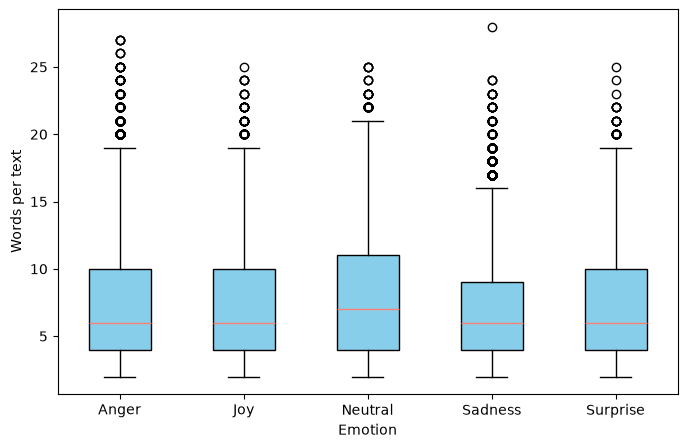

In [11]:
texts = unique_texts.assign(word_count=unique_texts["text"].str.split().str.len())

emotion_order = sorted(texts["emotion"].unique())

length_stats = texts.groupby("emotion")["word_count"].describe().loc[emotion_order]
length_stats.loc["All"] = texts["word_count"].describe()
display(length_stats.round(2))

print("Text Length Distribution per Emotion")
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([texts.loc[texts["emotion"] == e, "word_count"] for e in emotion_order], tick_labels=emotion_order,
           patch_artist=True, boxprops={"facecolor": static_cmap[1]}, medianprops={"color": static_cmap[0]})
ax.set_xlabel("Emotion")
ax.set_ylabel("Words per text")
plt.show()

### Vocabulary Analysis

#### Lemmatization and Stop-Word Removal

In [12]:
lemma_cache = Path("emotion_text_lemmas.csv")

if lemma_cache.exists():
    stanza_annotated = pd.read_csv(lemma_cache, keep_default_na=False)
else:
    stanza.download("lt")
    nlp = stanza.Pipeline("lt", processors="tokenize,pos,lemma", tokenize_pretokenized=True,
                          use_gpu=torch.cuda.is_available())
    lemmas, upos = [], []
    for start in range(0, len(texts), 5000):
        chunk = texts["text"].iloc[start:start + 5000]
        doc = nlp([t.split() for t in chunk])
        for sent in doc.sentences:
            lemmas.append(" ".join((w.lemma or w.text).lower() for w in sent.words))
            upos.append(" ".join(w.upos for w in sent.words))
    stanza_annotated = texts[["text", "emotion"]].assign(lemmas=lemmas, upos=upos)
    stanza_annotated.to_csv(lemma_cache, index=False, encoding="utf-8")

stanza_annotated.head()

,text,emotion,lemmas,upos
0,džiugios naujienos iš čekijos,Joy,džiugis naujiena iš čekija,ADJ NOUN ADP PROPN
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,Joy,sėkmė lydėti aš mokykla mokinys vilis,NOUN VERB PRON NOUN NOUN NOUN
2,čekijos sostinėje prahoje vykusiame tarptautin...,Joy,čekija sostinė praha vykti tarptautinis jaunas...,PROPN NOUN PROPN VERB ADJ ADJ NOUN NOUN
3,festivalyje laimėta pirmoji vieta,Joy,festivalis laimėti pirmas vieta,NOUN VERB NUM NOUN
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,Joy,didžiuoti ir džiaugti įspūdingas pasiekimas be...,VERB CCONJ VERB ADJ NOUN CCONJ VERB PROPN CCON...


In [13]:
spacy_cache = Path("emotion_text_lemmas_spacy.csv")

if spacy_cache.exists():
    spacy_annotated = pd.read_csv(spacy_cache, keep_default_na=False)
else:
    nlp_spacy = spacy.load("lt_core_news_sm", exclude=["parser", "ner"])
    nlp_spacy.tokenizer = lambda text: Doc(nlp_spacy.vocab, words=text.split())

    spacy_lemmas, spacy_upos = [], []
    for doc in nlp_spacy.pipe(texts["text"], batch_size=1000):
        spacy_lemmas.append(" ".join((t.lemma_ or t.text).lower() for t in doc))
        spacy_upos.append(" ".join(t.pos_ or "X" for t in doc))
    spacy_annotated = texts[["text", "emotion"]].assign(lemmas=spacy_lemmas, upos=spacy_upos)
    spacy_annotated.to_csv(spacy_cache, index=False, encoding="utf-8")

pd.DataFrame({
    "text": stanza_annotated["text"],
    "stanza_lemmas": stanza_annotated["lemmas"],
    "spacy_lemmas": spacy_annotated["lemmas"],
}).head(10)

,text,stanza_lemmas,spacy_lemmas
0,džiugios naujienos iš čekijos,džiugis naujiena iš čekija,džiugus naujiena iš čekija
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,sėkmė lydėti aš mokykla mokinys vilis,sėkmė lydėti aš mokykla mokinis vilė
2,čekijos sostinėje prahoje vykusiame tarptautin...,čekija sostinė praha vykti tarptautinis jaunas...,čekija sostinis praha vykusiame tarptautinis j...
3,festivalyje laimėta pirmoji vieta,festivalis laimėti pirmas vieta,festivalis laimėti pirmas vieta
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,didžiuoti ir džiaugti įspūdingas pasiekimas be...,didžiuojamė ir džiaugiamė įspūdingas pasiekima...
5,džiugios žinios šilumos liko laukti neilgai,džiugis žinios šiluma likti laukti neilgai,džiugus žinios šiluma likti laukti neilgai
6,džiugios naujienos mūsų alumnams,džiugis naujiena aš alumnas,džiugus naujiena aš alumnas
7,tampame partneriais su tarptautine programinės...,tapti partneris su tarptautinis programinis įr...,tampame partnerias su tarptautinis programinis...
8,savaitę pradedame geromis naujienomis,savaitė pradėti geras naujiena,savaitė pradedi gera naujienos
9,karantino metu galima lankytis lietuvos liaudi...,karanti metas galėti lankytis lietuva liaudis ...,karantinti metas galėti lankytis lietuva liaud...


In [14]:
tokens = pd.DataFrame({
    "word": stanza_annotated["text"].str.split(),
    "stanza_lemma": stanza_annotated["lemmas"].str.split(),
    "spacy_lemma": spacy_annotated["lemmas"].str.split(),
    "stanza_upos": stanza_annotated["upos"].str.split(),
    "spacy_upos": spacy_annotated["upos"].str.split(),
}).explode(["word", "stanza_lemma", "spacy_lemma", "stanza_upos", "spacy_upos"], ignore_index=True)

word_forms = tokens["word"].nunique()

summary = pd.DataFrame({"word forms": word_forms}, index=["Stanza", "spaCy"])
for name, column in [("Stanza", "stanza_lemma"), ("spaCy", "spacy_lemma")]:
    summary.loc[name, "distinct lemmas"] = tokens[column].nunique()
    summary.loc[name, "reduction ratio (%)"] = (1 - tokens[column].nunique() / word_forms) * 100
    summary.loc[name, "pass-through rate (%)"] = (tokens[column] == tokens["word"]).mean() * 100
display(summary.round(2))

print(f"Tokens with the same lemma: {(tokens['stanza_lemma'] == tokens['spacy_lemma']).mean():.1%}")
print(f"Tokens with the same UPOS tag: {(tokens['stanza_upos'] == tokens['spacy_upos']).mean():.1%}")

different = tokens[tokens["stanza_lemma"] != tokens["spacy_lemma"]]
different.groupby(["word", "stanza_lemma", "spacy_lemma"]).size().sort_values(ascending=False).head(15).to_frame("tokens")

,word forms,distinct lemmas,reduction ratio (%),pass-through rate (%)
Stanza,52814,30549.0,42.16,40.85
spaCy,52814,45688.0,13.49,50.80


Tokens with the same lemma: 78.9%
Tokens with the same UPOS tag: 81.6%


,,,tokens
word,stanza_lemma,spacy_lemma,
jūs,tu,jūs,1945
tai,tas,tai,1250
ačiū,atiti,ačiū,834
eik,eiti,eik,740
tai,tai,tas,664
neįtikėtina,neįtikėti,neįtikėtinti,580
nu,nūti,nu,508
dėkoju,dėkoti,dėkoju,456
žmones,žmogus,žmones,406


In [15]:
# spaCy is used as the main lemmatizer, POS tagger and source of stop words for the rest of the analysis
annotated = spacy_annotated.copy()

# Stop-word removal: drop stop words (surface form or lemma) and non-alphabetic tokens
stop_words = set(STOP_WORDS)
print(f"spaCy Lithuanian stop words: {len(stop_words)}")

# Additional stop words added manually
STOP_WORDS |= {"būti", "čia", "galėti", "turėti", "daug", "ten", "nu", 
               "tiek", "tada", "kam", "todėl", "žmogus", "dabar", "du", 
               "trys", "eik", "eiti", "labai", "diena", "gyvenimas", 
               "laikas", "metai", "norėti", "viskas"}
expanded_stop_words = set(STOP_WORDS)
print(f"Stop words including manually added words: {len(expanded_stop_words)}")

annotated["content_lemmas"] = [
    emoclass.remove_stop_words(t, l, expanded_stop_words) for t, l in zip(annotated["text"], annotated["lemmas"])
]

all_tokens = annotated["text"].str.split().explode()
all_lemmas = annotated["content_lemmas"].explode().dropna()
print(f"Tokens: {len(all_tokens)} -> {len(all_lemmas)} after stop-word removal")
print(f"Vocabulary: {all_tokens.nunique()} word forms -> {all_lemmas.nunique()} lemmas")
annotated[["text", "lemmas", "content_lemmas"]].head()

spaCy Lithuanian stop words: 1314
Stop words including manually added words: 1338
Tokens: 978027 -> 578791 after stop-word removal
Vocabulary: 52814 word forms -> 45181 lemmas


,text,lemmas,content_lemmas
0,džiugios naujienos iš čekijos,džiugus naujiena iš čekija,"[džiugus, naujiena, čekija]"
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,sėkmė lydėti aš mokykla mokinis vilė,"[sėkmė, lydėti, mokykla, mokinis, vilė]"
2,čekijos sostinėje prahoje vykusiame tarptautin...,čekija sostinis praha vykusiame tarptautinis j...,"[čekija, sostinis, praha, vykusiame, tarptauti..."
3,festivalyje laimėta pirmoji vieta,festivalis laimėti pirmas vieta,"[festivalis, laimėti, pirmas, vieta]"
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,didžiuojamė ir džiaugiamė įspūdingas pasiekima...,"[didžiuojamė, džiaugiamė, įspūdingas, pasiekim..."


#### Most Frequent Words per Emotion

In [16]:
lemma_counts = {
    e: Counter(l for tokens in group for l in tokens)
    for e, group in annotated.groupby("emotion")["content_lemmas"]
}

top_words = pd.DataFrame(
    {e: [f"{w} ({c})" for w, c in lemma_counts[e].most_common(50)] for e in emotion_order},
    index=range(1, 51),
)
display(top_words)

top50 = {e: {w for w, _ in lemma_counts[e].most_common(50)} for e in emotion_order}
shared_top = set.intersection(*top50.values())
print(f"Lemmas in the top 50 of all emotions ({len(shared_top)}): {', '.join(sorted(shared_top))}")

,Anger,Joy,Neutral,Sadness,Surprise
1,niekas (782),džiaugsmas (1522),miestas (1037),niekas (857),neįtikėtinti (747)
2,nebūti (545),širdis (840),vilnius (899),liūdna (482),patikėti (611)
3,reikėti (534),laimė (713),lietuva (712),nebūti (462),pasaulis (423)
4,negalėti (477),naujas (636),nebūti (693),atrodyti (448),nebūti (423)
5,sakyti (407),vaikas (556),sakyti (691),liūdesys (420),negalėti (393)
6,kartas (395),geras (555),darbas (665),negalėti (403),šimtas (369)
7,darbas (370),darbas (467),reikėti (566),mintis (392),žemė (362)
8,žodis (346),dėkoju (456),teatras (556),pasaulis (371),žinoja (348)
9,gerai (335),meilė (436),vieta (553),sakyti (293),pagalvoti (342)
10,žinoti (325),galas (389),tapti (532),sunkus (280),įsivaizduas (309)


Lemmas in the top 50 of all emotions (0): 


#### Word Clouds per Emotion

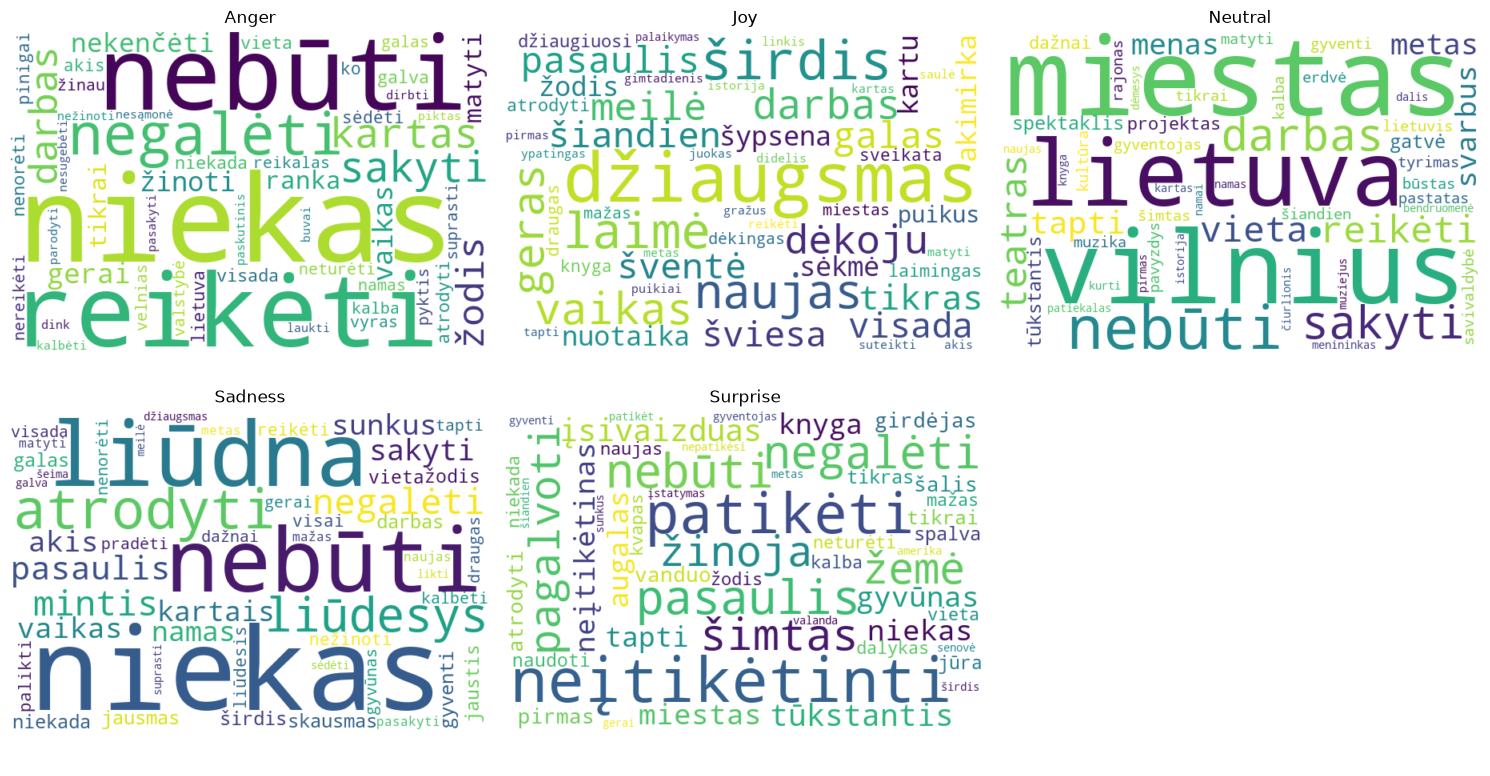

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, e in zip(axes.flat, emotion_order):
    cloud = WordCloud(width=600, height=400, background_color="white", max_words=50).generate_from_frequencies(lemma_counts[e])
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(e)
    ax.axis("off")
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

### Part-of-Speech (POS) Analysis

#### POS Tagging

In [18]:
pos_long = annotated[["emotion"]].assign(upos=annotated["upos"].str.split()).explode("upos", ignore_index=True)

pos_overall = pos_long["upos"].value_counts().to_frame("tokens")
pos_overall["share_pct"] = (pos_overall["tokens"] / pos_overall["tokens"].sum() * 100).round(1)
display(pos_overall)

for text, tags in zip(annotated["text"].head(3), annotated["upos"].head(3)):
    print(" ".join(f"{w}/{t}" for w, t in zip(text.split(), tags.split())))

,tokens,share_pct
upos,,
NOUN,286873,29.3
VERB,188489,19.3
PRON,92147,9.4
ADV,75275,7.7
ADJ,75106,7.7
CCONJ,50941,5.2
ADP,46546,4.8
DET,44099,4.5
PART,38629,3.9


džiugios/ADJ naujienos/NOUN iš/ADP čekijos/NOUN
sėkmė/NOUN lydėjo/VERB mūsų/PRON mokyklos/NOUN mokinį/ADJ vilių/NOUN
čekijos/NOUN sostinėje/ADJ prahoje/NOUN vykusiame/VERB tarptautiniame/ADJ jaunųjų/X atlikėjų/NOUN konkurse/NOUN


#### POS Tag Distributions per Emotion

Anger              Joy           Neutral           Sadness            \
      tokens share_pct tokens share_pct  tokens share_pct  tokens share_pct   
upos                                                                          
NOUN   45946     22.18  56599     31.73   82115     34.24   49511     27.18   
VERB   41243     19.91  30400     17.04   47149     19.66   37821     20.76   
PRON   31563     15.24  15064      8.44   13481      5.62   17731      9.73   
ADV    19831      9.58  12215      6.85   16751      6.99   14805      8.13   
ADJ    11626      5.61  17376      9.74   19986      8.33   12721      6.98   
CCONJ   9895      4.78  11246      6.30   12049      5.02    9926      5.45   
ADP    10056      4.86   8160      4.57   10881      4.54    9373      5.15   
DET    10255      4.95   9128      5.12    9205      3.84    8314      4.56   
PART   11195      5.41   5836      3.27    7928      3.31    7332      4.02   
SCONJ   8675      4.19   5897      3.31    7219      3.01    7573      4.16   
AUX     1833      0.89   2918      1.64    4706      1.96    2920      1.60   
X       3098      1.50   1888      1.06    3329      1.39    2654      1.46   
NUM     1157      0.56    930      0.52    2490      1.04     938      0.51   
PROPN    600      0.29    661      0.37    2411      1.01     455      0.25   
SYM       52      0.03     23      0.01      64      0.03      29      0.02   
INTJ      42      0.02     26      0.01      17      0.01      33      0.02   
PUNCT     37      0.02     13      0.01      14      0.01      27      0.01   
SPACE      7      0.00      0      0.00       0      0.00       2      0.00   

      Surprise            
        tokens share_pct  
upos                      
NOUN     52702     30.90  
VERB     31876     18.69  
PRON     14308      8.39  
ADV      11673      6.84  
ADJ      13397      7.85  
CCONJ     7825      4.59  
ADP       8076      4.73  
DET       7197      4.22  
PART      6338      3.72  
SCONJ     6912      4.05  
AUX       3424      2.01  
X         3786      2.22  
NUM       2322      1.36  
PROPN      656      0.38  
SYM         37      0.02  
INTJ        26      0.02  
PUNCT       19      0.01  
SPACE        2      0.00

POS Tag Distribution per Emotion


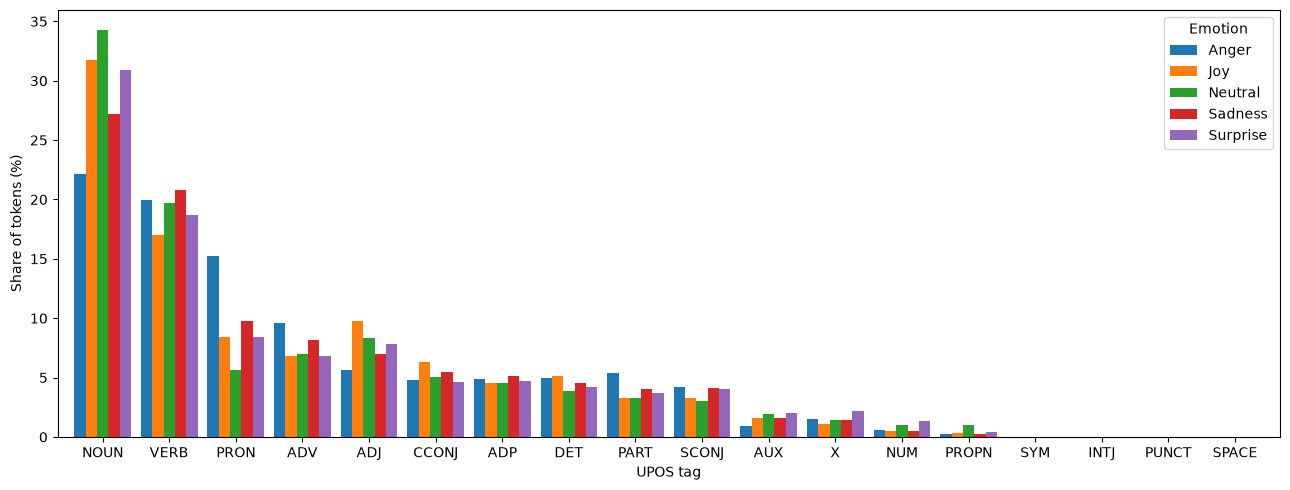

In [19]:
pos_counts = pd.crosstab(pos_long["emotion"], pos_long["upos"])[pos_overall.index].loc[emotion_order].T
pos_share = pos_counts / pos_counts.sum() * 100

pos_table = pd.concat(
    {e: pd.DataFrame({"tokens": pos_counts[e], "share_pct": pos_share[e].round(2)}) for e in emotion_order},
    axis=1,
)
display(pos_table)

print("POS Tag Distribution per Emotion")
fig, ax = plt.subplots(figsize=(13, 5))
pos_share.plot.bar(ax=ax, width=0.85, rot=0)
ax.set_xlabel("UPOS tag")
ax.set_ylabel("Share of tokens (%)")
ax.legend(title="Emotion")
plt.tight_layout()
plt.show()

In [20]:
# "Other" is determined separately for each emotion: tags with a share of 5% or less within that emotion
other_tags = {e: pos_share.index[pos_share[e] <= 5] for e in pos_share.columns}
for e, tags in other_tags.items():
    print(f"{e}: Other = {len(tags)} tags: {', '.join(tags)}")

other_share = pd.DataFrame({e: [pos_share.loc[tags, e].sum()] for e, tags in other_tags.items()}, index=["Other (%)"])

overall_share = pos_overall["tokens"] / pos_overall["tokens"].sum() * 100
other_share["All"] = overall_share[overall_share <= 5].sum()
other_share.round(2)

Anger: Other = 12 tags: CCONJ, ADP, DET, SCONJ, AUX, X, NUM, PROPN, SYM, INTJ, PUNCT, SPACE
Joy: Other = 11 tags: ADP, PART, SCONJ, AUX, X, NUM, PROPN, SYM, INTJ, PUNCT, SPACE
Neutral: Other = 12 tags: ADP, DET, PART, SCONJ, AUX, X, NUM, PROPN, SYM, INTJ, PUNCT, SPACE
Sadness: Other = 11 tags: DET, PART, SCONJ, AUX, X, NUM, PROPN, SYM, INTJ, PUNCT, SPACE
Surprise: Other = 13 tags: CCONJ, ADP, DET, PART, SCONJ, AUX, X, NUM, PROPN, SYM, INTJ, PUNCT, SPACE


,Anger,Joy,Neutral,Sadness,Surprise,All
Other (%),22.07,14.77,20.13,16.62,27.33,21.39


## 3. Text Representation (Feature Extraction)

### Stratified Training and Test Split

In [21]:
x_train, x_test, y_train, y_test = train_test_split(
    annotated["text"], annotated["emotion"], test_size=0.2, stratify=annotated["emotion"], random_state=random_seed
)

counts = pd.DataFrame({
    "full_sample": annotated["emotion"].value_counts(),
    "train_sample": y_train.value_counts(),
    "test_sample": y_test.value_counts(),
}).loc[emotion_order]
counts.loc["Total"] = counts.sum()

split_sizes = pd.DataFrame({
    "full_sample": counts["full_sample"],
    "full_sample_pct": (counts["full_sample"] / counts.loc["Total", "full_sample"] * 100).round(1),
    "train_sample": counts["train_sample"],
    "test_sample": counts["test_sample"],
    "train_sample_pct": (counts["train_sample"] / counts["full_sample"] * 100).round(1),
    "test_sample_pct": (counts["test_sample"] / counts["full_sample"] * 100).round(1),
})
split_sizes

,full_sample,full_sample_pct,train_sample,test_sample,train_sample_pct,test_sample_pct
emotion,,,,,,
Anger,28057,20.8,22445,5612,80.0,20.0
Joy,24997,18.5,19998,4999,80.0,20.0
Neutral,30982,23.0,24785,6197,80.0,20.0
Sadness,26687,19.8,21350,5337,80.0,20.0
Surprise,24228,18.0,19382,4846,80.0,20.0
Total,134951,100.0,107960,26991,80.0,20.0


### Frequency-Based Representation

In [22]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

print(f"TF-IDF matrix (train): {x_train_tfidf.shape}")

TF-IDF matrix (train): (107960, 125814)


### Static Word Embeddings

In [23]:
w2v = Word2Vec([t.split() for t in x_train], window=5, min_count=2, epochs=10, workers=4, seed=random_seed)

x_train_w2v = emoclass.average_word_vectors(x_train, w2v.wv)
x_test_w2v = emoclass.average_word_vectors(x_test, w2v.wv)

print(f"Word2Vec vocabulary: {len(w2v.wv)} words")
print(f"Word2Vec matrix (train): {x_train_w2v.shape}")

Word2Vec vocabulary: 33761 words
Word2Vec matrix (train): (107960, 100)


### Contextual Embeddings

In [24]:
sbert_cache = Path(f"sbert_embeddings_{random_seed}.npz")

if sbert_cache.exists():
    cached = np.load(sbert_cache)
    x_train_sbert, x_test_sbert = cached["train"], cached["test"]
else:
    sbert = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2",
                                device="cuda" if torch.cuda.is_available() else "cpu")
    x_train_sbert = sbert.encode(x_train.tolist(), batch_size=256, show_progress_bar=True)
    x_test_sbert = sbert.encode(x_test.tolist(), batch_size=256, show_progress_bar=True)
    np.savez(sbert_cache, train=x_train_sbert, test=x_test_sbert)

print(f"Sentence-BERT matrix (train): {x_train_sbert.shape}")

Sentence-BERT matrix (train): (107960, 384)


### Representation Comparison

#### Dimensionality

In [25]:
representations = {
    "TF-IDF": x_train_tfidf,
    "Word2Vec": x_train_w2v,
    "Sentence-BERT": x_train_sbert,
}

pd.DataFrame({name: {"dimensions": x.shape[1]} for name, x in representations.items()}).T

,dimensions
TF-IDF,125814
Word2Vec,100
Sentence-BERT,384


#### Sparsity

In [26]:
pd.DataFrame({"zero values (%)": {name: round(emoclass.zero_share(x), 2) for name, x in representations.items()}})

,zero values (%)
TF-IDF,99.99
Word2Vec,0.05
Sentence-BERT,0.00


#### Semantic Information

Check corrctness

In [27]:
probe_words = ["džiaugsmas", "pyktis", "baimė", "liūdesys", "nuostaba"]
probe_words = [w for w in probe_words if w in w2v.wv]

pd.DataFrame({
    w: [f"{n} ({s:.2f})" for n, s in w2v.wv.most_similar(w, topn=5)] for w in probe_words
}, index=range(1, 6))

,džiaugsmas,pyktis,baimė,liūdesys,nuostaba
1,laimė (0.79),kantrybė (0.76),fobofobija (0.77),gyvenimas (0.71),žalkauskaitė (0.93)
2,neapsakomas (0.74),ugnis (0.74),pamišėliai (0.76),meilė (0.68),išsiliedavęs (0.92)
3,darbuotojui (0.73),religija (0.74),lydeka (0.76),džiaugsmas (0.67),alegro (0.92)
4,juokas (0.73),prakeiksmas (0.73),karpis (0.75),egzistencinis (0.67),pasismauk (0.92)
5,suima (0.71),baigėsi (0.73),fobija (0.75),priešas (0.65),liūdnoje (0.92)


## 4. Emotion Classification

### Logistic Regression Setup

In [28]:
log_reg_params = {"max_iter": 1000, "random_state": random_seed}
results = {}

### Frequency-Based Representation Model

In [29]:
model_tfidf = LogisticRegression(**log_reg_params).fit(x_train_tfidf, y_train)
results["TF-IDF"] = emoclass.evaluate(model_tfidf, x_test_tfidf, y_test)

#### Classification Metrics

In [30]:
results["TF-IDF"]["report"].round(4)

,accuracy,precision,recall,f1,true_class_proba,support
Anger,0.9655,0.8999,0.9387,0.9189,0.6846,5612.0
Joy,0.9720,0.9415,0.9050,0.9229,0.6697,4999.0
Neutral,0.9653,0.9069,0.9461,0.9261,0.6857,6197.0
Sadness,0.9639,0.9121,0.9046,0.9084,0.6237,5337.0
Surprise,0.9690,0.9381,0.8855,0.9110,0.6289,4846.0
macro avg,0.9671,0.9197,0.9160,0.9175,0.6585,26991.0
micro avg,0.9179,0.9179,0.9179,0.9179,0.6600,26991.0


#### Confusion Matrix

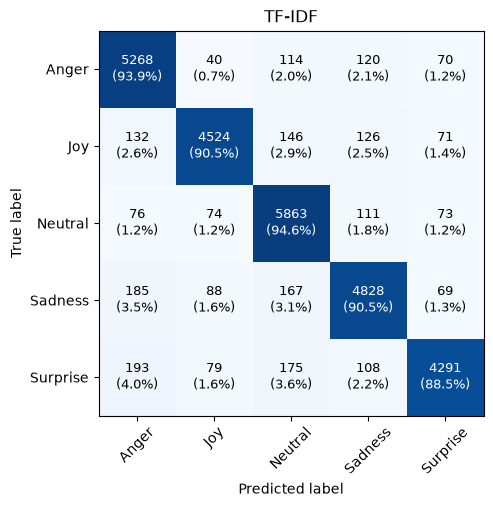

In [31]:
fig, ax = plt.subplots(figsize=(6, 5))
emoclass.plot_confusion_matrix(y_test, results["TF-IDF"]["y_pred"], emotion_order, ax, "TF-IDF")
plt.show()

In [32]:
results["TF-IDF"]["mean_proba"].round(3)

,Anger,Joy,Neutral,Sadness,Surprise
Anger,0.685,0.065,0.074,0.093,0.082
Joy,0.077,0.670,0.092,0.091,0.070
Neutral,0.070,0.076,0.686,0.092,0.077
Sadness,0.101,0.086,0.104,0.624,0.086
Surprise,0.102,0.074,0.100,0.095,0.629


### Static Word Embedding Model

In [33]:
model_w2v = LogisticRegression(**log_reg_params).fit(x_train_w2v, y_train)
results["Word2Vec"] = emoclass.evaluate(model_w2v, x_test_w2v, y_test)

#### Classification Metrics

In [34]:
results["Word2Vec"]["report"].round(4)

,accuracy,precision,recall,f1,true_class_proba,support
Anger,0.8070,0.5320,0.5953,0.5619,0.4058,5612.0
Joy,0.8442,0.5901,0.5207,0.5532,0.4176,4999.0
Neutral,0.7657,0.4920,0.6321,0.5533,0.3966,6197.0
Sadness,0.7657,0.3931,0.3399,0.3645,0.2688,5337.0
Surprise,0.8122,0.4701,0.3611,0.4084,0.3017,4846.0
macro avg,0.7990,0.4954,0.4898,0.4883,0.3581,26991.0
micro avg,0.4974,0.4974,0.4974,0.4974,0.3601,26991.0


#### Confusion Matrix

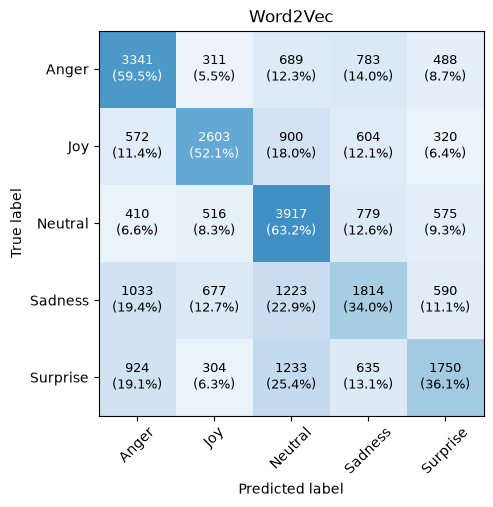

In [35]:
fig, ax = plt.subplots(figsize=(6, 5))
emoclass.plot_confusion_matrix(y_test, results["Word2Vec"]["y_pred"], emotion_order, ax, "Word2Vec")
plt.show()

In [36]:
results["Word2Vec"]["mean_proba"].round(3)

,Anger,Joy,Neutral,Sadness,Surprise
Anger,0.406,0.114,0.127,0.193,0.160
Joy,0.132,0.418,0.167,0.171,0.114
Neutral,0.117,0.139,0.397,0.181,0.167
Sadness,0.200,0.165,0.201,0.269,0.165
Surprise,0.188,0.117,0.215,0.179,0.302


### Contextual Embedding Model

In [37]:
model_sbert = LogisticRegression(**log_reg_params).fit(x_train_sbert, y_train)
results["Sentence-BERT"] = emoclass.evaluate(model_sbert, x_test_sbert, y_test)

#### Classification Metrics

In [38]:
results["Sentence-BERT"]["report"].round(4)

,accuracy,precision,recall,f1,true_class_proba,support
Anger,0.8434,0.6145,0.6622,0.6374,0.5169,5612.0
Joy,0.8852,0.7121,0.6383,0.6732,0.5598,4999.0
Neutral,0.8348,0.6255,0.6995,0.6604,0.5436,6197.0
Sadness,0.8242,0.5568,0.5432,0.5499,0.4350,5337.0
Surprise,0.8522,0.5991,0.5347,0.5650,0.4425,4846.0
macro avg,0.8480,0.6216,0.6156,0.6172,0.4995,26991.0
micro avg,0.6199,0.6199,0.6199,0.6199,0.5014,26991.0


#### Confusion Matrix

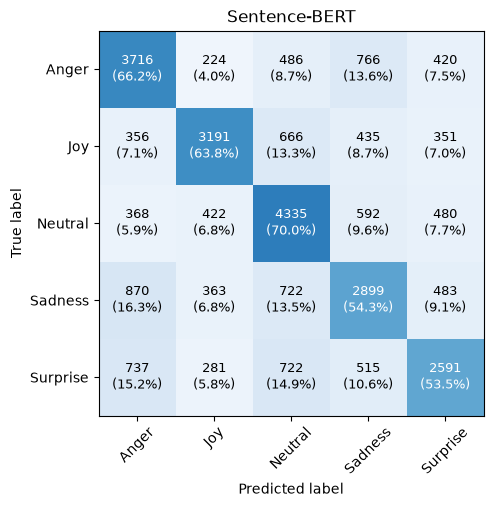

In [39]:
fig, ax = plt.subplots(figsize=(6, 5))
emoclass.plot_confusion_matrix(y_test, results["Sentence-BERT"]["y_pred"], emotion_order, ax, "Sentence-BERT")
plt.show()

In [40]:
results["Sentence-BERT"]["mean_proba"].round(3)

,Anger,Joy,Neutral,Sadness,Surprise
Anger,0.517,0.075,0.102,0.173,0.133
Joy,0.086,0.560,0.140,0.114,0.100
Neutral,0.092,0.115,0.544,0.125,0.124
Sadness,0.182,0.104,0.149,0.435,0.130
Surprise,0.158,0.100,0.161,0.138,0.442


## 5. Results Comparison

### Comparative Results Table

In [41]:
metric_columns = ["precision", "recall", "f1", "true_class_proba"]

comparison = pd.DataFrame({
    name: {"accuracy": r["accuracy"], **r["report"].loc["macro avg", metric_columns]}
    for name, r in results.items()
}).T

comparison.round(4)

,accuracy,precision,recall,f1,true_class_proba
TF-IDF,0.9179,0.9197,0.9160,0.9175,0.6585
Word2Vec,0.4974,0.4954,0.4898,0.4883,0.3581
Sentence-BERT,0.6199,0.6216,0.6156,0.6172,0.4995


### Confusion Matrix Comparison

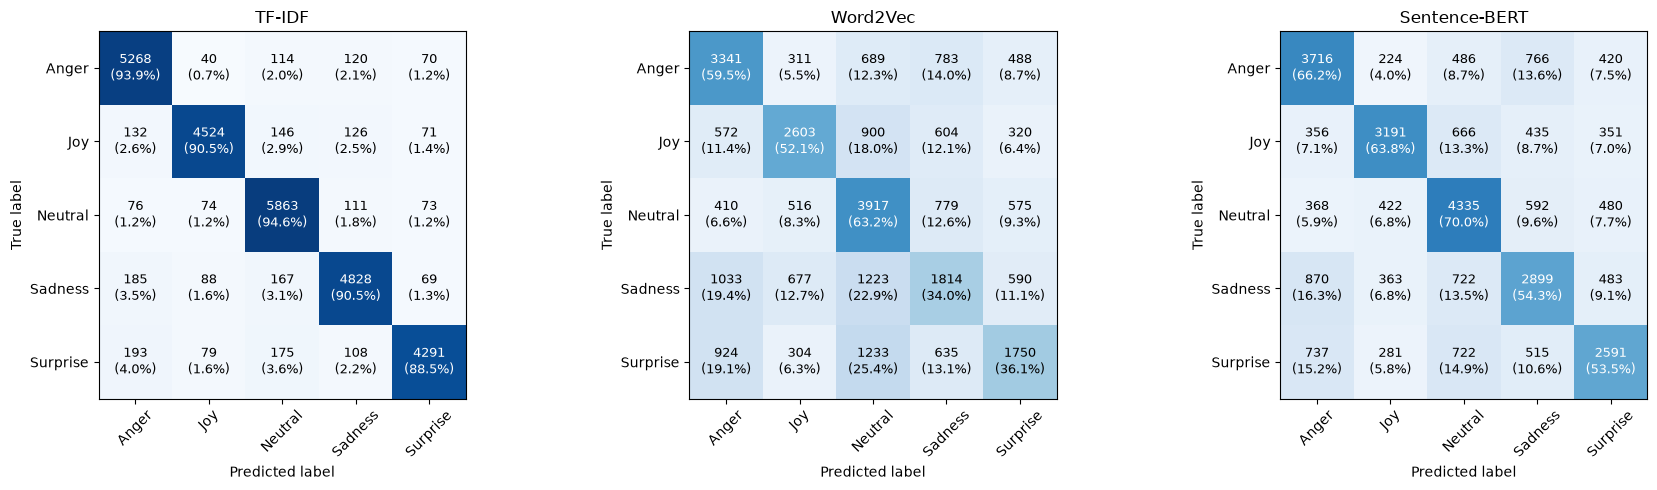

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, r) in zip(axes, results.items()):
    emoclass.plot_confusion_matrix(y_test, r["y_pred"], emotion_order, ax, name)

plt.tight_layout()
plt.show()

### Most Common Classification Errors

In [43]:
top_errors = {}
for name, r in results.items():
    wrong = pd.DataFrame({"true": np.asarray(y_test), "predicted": r["y_pred"]}).query("true != predicted")
    top_errors[name] = [f"{t} -> {p} ({n})" for (t, p), n in wrong.value_counts().head(5).items()]

pd.DataFrame(top_errors, index=range(1, 6))

,TF-IDF,Word2Vec,Sentence-BERT
1,Surprise -> Anger (193),Surprise -> Neutral (1233),Sadness -> Anger (870)
2,Sadness -> Anger (185),Sadness -> Neutral (1223),Anger -> Sadness (766)
3,Surprise -> Neutral (175),Sadness -> Anger (1033),Surprise -> Anger (737)
4,Sadness -> Neutral (167),Surprise -> Anger (924),Surprise -> Neutral (722)
5,Joy -> Neutral (146),Joy -> Neutral (900),Sadness -> Neutral (722)
